# Librerias

In [1]:
import sys
import os
import datetime

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, PReLU, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from keras.metrics import Precision, Recall, AUC
import keras

from src.Modelo_ANN import Regression_Model

I0000 00:00:1791835564.225722 2167019 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Carga de subsets

In [2]:
subsets = ['X_train_scaled', 'y_train', 'X_test_scaled', 'y_test', 'validation_set']

paths = ['../data/partitions/X_train_scaled.csv',
         '../data/partitions/y_train.csv',
         '../data/partitions/X_test_scaled.csv',
         '../data/partitions/y_test.csv',
         '../data/partitions/validation_set.parquet']



In [3]:
subsets

['X_train_scaled', 'y_train', 'X_test_scaled', 'y_test', 'validation_set']

In [4]:
regression_model = Regression_Model(*subsets, paths)

In [5]:
regression_model.set_partitions()

In [6]:
regression_model.partitions.keys()

dict_keys(['X_train_scaled', 'y_train', 'X_test_scaled', 'y_test', 'validation_set'])

In [7]:
# Ejecuta esto en una celda para inspeccionar los tamaños
print("Dimensiones de X_train:", regression_model.partitions[regression_model.x_train_file_name].shape)
print("Dimensiones de Y_train:", regression_model.partitions[regression_model.y_train_file_name].shape)
print("Dimensiones de X_test:", regression_model.partitions[regression_model.x_test_file_name].shape)
print("Dimensiones de Y_test:", regression_model.partitions[regression_model.y_test_file_name].shape)


Dimensiones de X_train: (5616, 20)
Dimensiones de Y_train: (5616, 1)
Dimensiones de X_test: (1404, 20)
Dimensiones de Y_test: (1404, 1)


# Carga de scaler

In [8]:
regression_model.save_load_scaler('../models/scaler.pkl', load= True)

# Configuracion de flujo y entrenamineto

In [16]:
tf.config.experimental.enable_op_determinism()

beta = 0.99# Hiperparámetro a ajustar
pesos_dict = {}
for c in np.unique(regression_model.partitions[regression_model.y_train_file_name]):
    n_j = np.sum(regression_model.partitions[regression_model.y_train_file_name].to_numpy() == c)
    pesos_dict[c] = (1.0 - beta) / (1.0 - np.power(beta, n_j))

regression_model.preparar_experimento(
    45
                                  
).model_flow_settings(
    capas = 6, 
    fun_act = 'LeakyReLU',
    loss = 'binary_crossentropy',
    optimizer = 'adam',
    n_output = 1,
    dropout = 0.4,
    fun_out= 'sigmoid',
    leakyrelu_negative_slope = 0.5,
    n_down = 0.5
).start_training(
    epochs = 600,
    w_balance= True,
    w_dict = pesos_dict,
    batch_size = 200, 
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=25,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../models/checkpoints/regression_model.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)

Epoch 1/600


/home/hadoop/CUC/IA_Aplicada/Proyecto_Abandono_Clientes/.IA_Abandono_wsl/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
E0000 00:00:1791835860.317548 2167019 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMap

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0068 - prc: 0.2558 - val_loss: 0.6088 - val_prc: 0.2646
Epoch 2/600
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0064 - prc: 0.2634 - val_loss: 0.5893 - val_prc: 0.3890
Epoch 3/600
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0061 - prc: 0.3068 - val_loss: 0.5679 - val_prc: 0.5037
Epoch 4/600
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0059 - prc: 0.3303 - val_loss: 0.5415 - val_prc: 0.5554
Epoch 5/600
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0057 - prc: 0.3928 - val_loss: 0.5171 - val_prc: 0.5831
Epoch 6/600
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0056 - prc: 0.4191 - val_loss: 0.5017 - val_prc: 0.6048
Epoch 7/600
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0054 - prc: 0.4407 - val_loss: 0.4889 - val_prc: 0.6106
Epoch 8/600
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0054 - prc: 0.4496 - val_loss: 0.4817 - val_prc: 0.6177
Epoch 9/600
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0054 - prc: 0.

<Axes: >

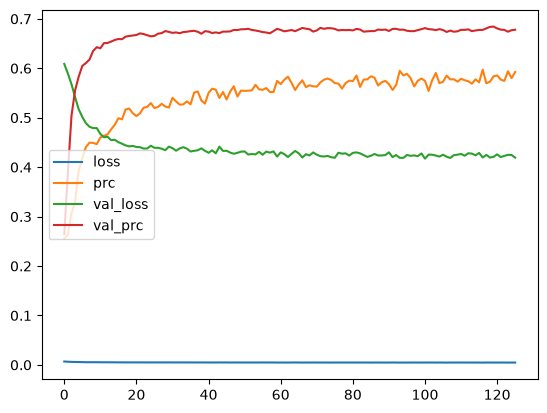

In [17]:
losses = pd.DataFrame(regression_model.model.history.history)

losses.plot()

# Evaluacion

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Reporte de clasificacion:
               precision    recall  f1-score   support

         0.0       0.61      1.00      0.76        14
         1.0       0.00      0.00      0.00         9

    accuracy                           0.61        23
   macro avg       0.30      0.50      0.38        23
weighted avg       0.37      0.61      0.46        23
 

Matriz de confucion:
                        No abandona(predict) (0)  Abandona(predict) (1)
No abandona(real) (0)                        14                      0
Abandona(real) (1)                            9                      0
MAE:
 0.3707733663689831 

RMSE:
 0.4508283877952415 

¿En qué porcentaje nos estamos equivocando respecto a la media?
 0.9475319362762902 

¿En qué porcentaje nos estamos equivocando respecto a la mediana?
 Divicion entre 0 



E0000 00:00:1791835878.856590 2167019 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
/home/hadoop/CUC/IA_Aplicada/Proyecto_Abandono_Clientes/.IA_Abandono_wsl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _war

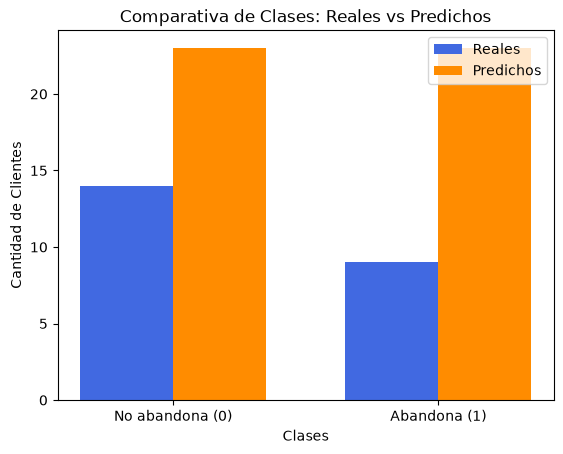

In [18]:
regression_model.make_prediction(target= 'Abandono', eval= True)

In [19]:
regression_model.data

,Adulto_Mayor,Pareja,Dependientes,Antiguedad(Meses),Servicio_Telefono,Lineas_Multiples,Internet_DSL,Internet_Fiber optic,Seguridad_Online,Copia_Seguridad_Online,...,Streaming_TV,Streaming_Peliculas,Contrato,Facturacion_Electronica,MP_Electronic check,MP_Mailed check,MP_Bank transfer (automatic),Cargos_Mensuales,Abandono,Prop_Abandono
0,0.0,0.0,1.0,31.0,1.0,1.0,1.0,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,0.0,1.0,0.0,79.45,1.0,0.164027
1,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,19.90,1.0,0.307077
2,0.0,0.0,0.0,16.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,19.70,1.0,0.211167
3,0.0,0.0,0.0,10.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,84.70,1.0,0.333951
4,1.0,1.0,0.0,12.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,80.45,1.0,0.576445
5,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,73.00,1.0,0.701499
6,1.0,1.0,0.0,44.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,30.35,1.0,0.273424
7,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,20.55,1.0,0.259872
8,0.0,0.0,0.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,76.95,1.0,0.722464
9,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,20.15,0.0,0.227408


In [20]:
regression_model.make_prediction(
    data = regression_model.partitions[regression_model.val_file_name],
    target = 'Abandono'
).predictions.apply(lambda x: x*100)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


,0
0,16.402670
1,30.707726
2,21.116724
3,33.395134
4,57.644516
5,70.149918
6,27.342426
7,25.987169
8,72.246368
9,22.740831


In [21]:
# Una vez terminado model.fit(...)
#nombre_archivo = '../models/regression_model_74_accur.keras'

# Guardar el modelo completo
#regression_model.model.save(nombre_archivo)
#print(f"Modelo guardado exitosamente en: {nombre_archivo}")
